In [ ]:
#Step 0 - Import Libraries and File Names
import pandas as pd
import matplotlib.pyplot as plt

POSTS_FILE = r"D:\\ict\sem5\\ML\\LHC\\LHC1\\Arjun_Assignment_data-20220427T165022Z-002\\Arjun_Assignment_data\\dataset-20210607T020316Z-001\dataset\\posts_short.csv"
USERS_FILE = r"D:\\ict\\sem5\\ML\\LHC\\LHC1\\Arjun_Assignment_data-20220427T165022Z-002\\Arjun_Assignment_data\\dataset-20210607T020316Z-002\\dataset\\users.csv"
POSTS_LONG_FILE = r"D:\\ict\\sem5\\ML\\LHC\\LHC1\\Arjun_Assignment_data-20220427T165022Z-002\\Arjun_Assignment_data\\dataset-20210607T020316Z-001\dataset\\posts_long.csv"

In [ ]:
#Step 1 - Load the Users Data
users = pd.read_csv(USERS_FILE, usecols=["id", "display_name", "reputation", "creation_date", "views"])

print("Total users:", len(users))

Total users: 9321924


rep_group
1             6358855
2-10           819976
11-100        1472304
101-1000       527715
Above 1000     143074
Name: count, dtype: int64
Most common group: 1
Share of most common group: 68.21 %


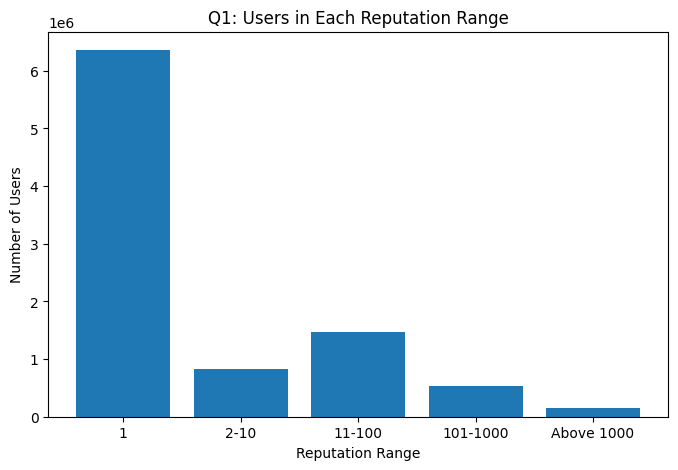

In [ ]:
#Q1 - How Are All Users Spread Across Reputation Ranges?
bins = [0, 2, 11, 101, 1001, float("inf")]
labels = ["1", "2-10", "11-100", "101-1000", "Above 1000"]
users["rep_group"] = pd.cut(users["reputation"], bins=bins, labels=labels, right=False)
rep_counts = users["rep_group"].value_counts().sort_index()

print(rep_counts)
print("Most common group:", rep_counts.idxmax())
print("Share of most common group:", round(rep_counts.max() / rep_counts.sum() * 100, 2), "%")

plt.figure(figsize=(8, 5))
plt.bar(rep_counts.index, rep_counts.values)
plt.title("Q1: Users in Each Reputation Range")
plt.xlabel("Reputation Range")
plt.ylabel("Number of Users")
plt.show()

year
2008    117307.0
2009     72187.0
2010     46193.0
2011     32603.0
2012     21894.0
2013     15776.0
2014      7141.0
2015      3580.0
2016      1944.0
2017       693.0
2018       126.0
Name: view_count, dtype: float64
Year with highest average views: 2008


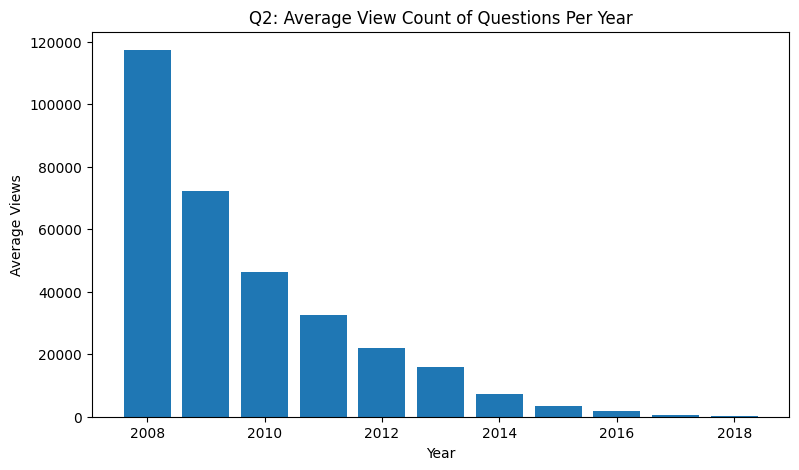

In [ ]:
#Q2 - What Is the Average View Count of Questions in Each Year?
posts = pd.read_csv(POSTS_FILE, usecols=["post_type_id", "creation_date", "view_count"])

questions = posts[posts["post_type_id"] == 1].copy()
questions["creation_date"] = pd.to_datetime(questions["creation_date"], errors="coerce")
questions = questions.dropna(subset=["creation_date"])
questions["year"] = questions["creation_date"].dt.year

avg_views = questions.groupby("year")["view_count"].mean().round(0)

print(avg_views)
print("Year with highest average views:", avg_views.idxmax())

plt.figure(figsize=(9, 5))
plt.bar(avg_views.index, avg_views.values)
plt.title("Q2: Average View Count of Questions Per Year")
plt.xlabel("Year")
plt.ylabel("Average Views")
plt.show()

                                                    title  comment_count
564808  Navigating to the another actvity app getting ...             70
565093   Silent pushes not delivered to the app on iOS 11             58
623063  Is there still a reason to use `int` in C++ code?             56
92707   Why do browsers match CSS selectors from right...             53
641722  Why does setTimeout behave incorrectly inside ...             51
547985                      Enhanced REP MOVSB for memcpy             50
71872   What's the rationale for null terminated strings?             45
128283                          How do you import a font?             45
478469                    tan dosent work properly on C++             45
468359  Why does the enhanced GCC 6 optimizer break pr...             44


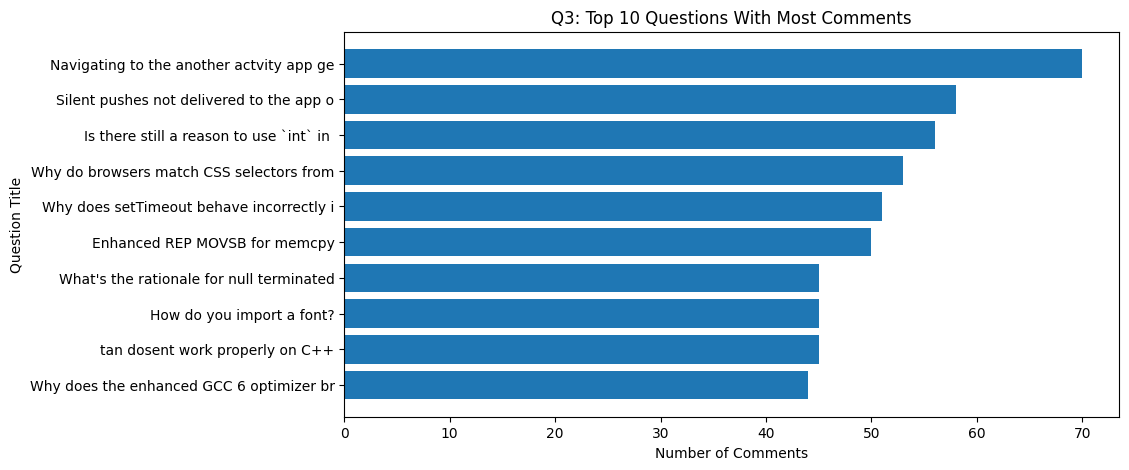

In [ ]:
# Q3 - Which 10 Questions Have the Most Comments?
posts_long = pd.read_csv(POSTS_LONG_FILE, usecols=["post_type_id", "title", "comment_count"])

questions_long = posts_long[posts_long["post_type_id"] == 1]
top_comments = questions_long.nlargest(10, "comment_count").copy()
top_comments["short_title"] = top_comments["title"].str[:40]

print(top_comments[["title", "comment_count"]])

plt.figure(figsize=(10, 5))
plt.barh(top_comments["short_title"], top_comments["comment_count"])
plt.gca().invert_yaxis()
plt.title("Q3: Top 10 Questions With Most Comments")
plt.xlabel("Number of Comments")
plt.ylabel("Question Title")
plt.show()

creation_date
2008      21689
2009      78159
2010     199550
2011     359548
2012     680777
2013    1125990
2014    1179441
2015    1258513
2016    1559780
2017    1737772
2018    1120705
Name: count, dtype: int64
Year with most new users: 2017


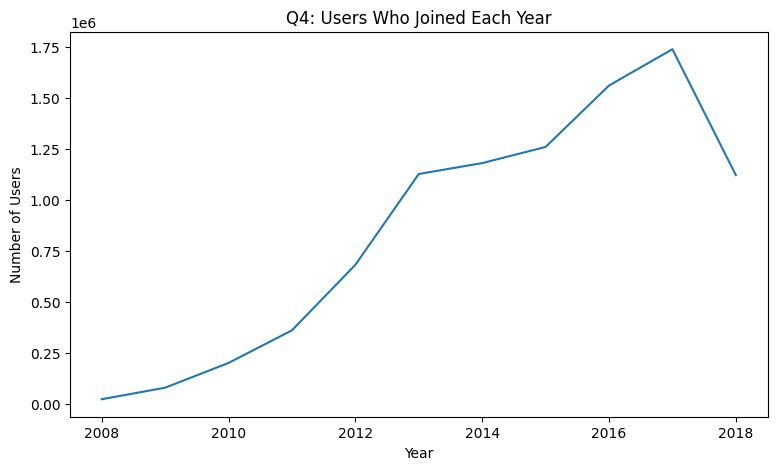

In [ ]:
# Q4 - How Many Users Joined Stack Overflow in Each Year?
join_year = pd.to_datetime(users["creation_date"], errors="coerce").dt.year.dropna().astype(int)
users_per_year = join_year.value_counts().sort_index()

print(users_per_year)
print("Year with most new users:", users_per_year.idxmax())

plt.figure(figsize=(9, 5))
plt.plot(users_per_year.index, users_per_year.values)
plt.title("Q4: Users Who Joined Each Year")
plt.xlabel("Year")
plt.ylabel("Number of Users")
plt.show()

           display_name    views  reputation
11389         Jon Skeet  1684703     1047863
1           Jeff Atwood   408587       44300
32433      Eric Lippert   378278      516573
54439            BalusC   375585      818687
11665      Marc Gravell   252237      754947
13975    Darin Dimitrov   246864      814505
9007       Hans Passant   229514      768855
663365    Gordon Linoff   215806      715788
40731       CommonsWare   212187      742577
35990   Martijn Pieters   208998      669040
Users common in both top 10 lists: 8


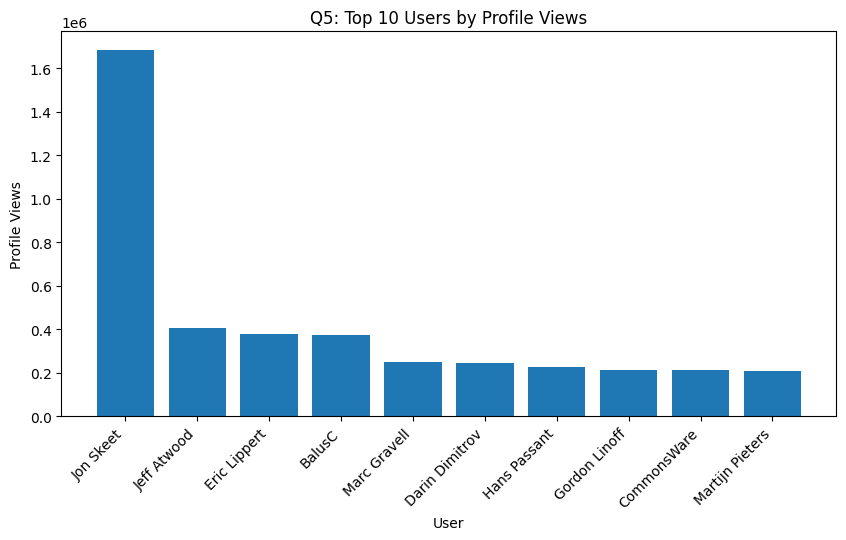

In [ ]:
# Q5 - Which 10 Users Have the Most Profile Views?
top_views = users.nlargest(10, "views")
top_reputation = users.nlargest(10, "reputation")

print(top_views[["display_name", "views", "reputation"]])

common = top_views["id"].isin(top_reputation["id"]).sum()
print("Users common in both top 10 lists:", common)

plt.figure(figsize=(10, 5))
plt.bar(top_views["display_name"], top_views["views"])
plt.title("Q5: Top 10 Users by Profile Views")
plt.xlabel("User")
plt.ylabel("Profile Views")
plt.xticks(rotation=45, ha="right")
plt.show()